# Étape 17 : probabilité de victoire minute par minute, GRU contre LightGBM

Jusqu'ici, on prédisait le vainqueur **à une seule minute, la 15ᵉ** : une photo de la partie.
On passe au **film** : une probabilité de victoire du bleu **à chaque minute**, de la 1ʳᵉ à la
fin. C'est la courbe que montrera l'appli Streamlit.

Trois modèles, du plus simple au plus riche :

| Modèle | Ce qu'il voit à la minute t | Idée |
|---|---|---|
| **Logistique par minute** | l'état à la minute t | une régression logistique de l'étape 13 **par minute** |
| **LightGBM empilé** | l'état à la minute t + la minute | **un seul** LightGBM pour toutes les minutes |
| **GRU** | **toutes** les minutes de 1 à t, dans l'ordre | un réseau récurrent qui lit la partie comme un film |

La question de l'étape : **lire l'historique de la partie (GRU) apporte-t-il quelque chose par
rapport à la photo de l'instant (logistique, LightGBM) ?**

Les règles anti-fuite, plus nombreuses qu'à 15 min :
1. à la minute t, on n'utilise que ce qui s'est passé **avant** t ;
2. la **dernière frame** de chaque partie (l'instant exact de la fin) est retirée ;
3. toutes les minutes d'une partie restent **du même côté** du découpage (entraînement,
   validation ou test) : on découpe des **parties**, jamais des lignes ;
4. le test est le même qu'aux étapes 13 à 16 (les 20 % de parties les plus récentes),
   regardé **une seule fois**, à la partie 5.

Plan :
1. Les données minute par minute
2. Des données en 3 dimensions pour le GRU
3. Les trois modèles, et un premier entraînement du GRU
4. Validation croisée chronologique (par partie)
5. Le test, une seule fois
6. Une partie racontée par les trois modèles
7. Conclusions

## 1. Les données minute par minute

`build_minute_features()` (dans `src/sequences.py`) renvoie un tableau **long** : une ligne par
(partie, minute). Mêmes 11 écarts bleu − rouge qu'à l'étape 12 (or, XP, CS, kills, tours,
plaques, dragons, larves, premiers objectifs), plus 5 variables qui comptent surtout **après**
15 minutes : héraut, **baron**, **dragon ancestral**, **inhibiteurs**, et les kills de la
**dernière minute** (qui est en surnombre en ce moment).

On part des parties de `build_features()` : exactement les mêmes qu'aux étapes 12 à 16, donc le
même découpage chronologique et **le même test**.

Compter 10 à 30 secondes pour la lecture de la base.

In [1]:
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

from features import FEATURES, TARGET, build_features, time_split
from models import evaluate, paired_bootstrap
from sequences import (SEQ_FEATURES, TIME, PerMinuteLogit, SequenceGRU, StackedLGBM,
                       bootstrap_games, build_minute_features, check_against_15,
                       cross_validate_minutes, scores_by_minute, split_games, to_padded)

pd.set_option("display.width", 140)
plt.rcParams.update({"figure.figsize": (10, 4.5), "axes.grid": True, "grid.alpha": 0.3})
COLORS = {"Logit par minute": "tab:blue", "LightGBM": "tab:orange", "GRU": "tab:green"}

t0 = time.time()
games = build_features()
games_train, games_test = time_split(games, 0.2)
long = build_minute_features(games)
train, test = split_games(long, games_train, games_test)
print(f"lu en {time.time() - t0:.0f} s")
print(f"{len(games)} parties -> {len(long)} lignes (partie, minute), "
      f"{len(long) / len(games):.1f} minutes par partie en moyenne")
print(f"entraînement : {train['match_id'].nunique()} parties, {len(train)} lignes | "
      f"test : {test['match_id'].nunique()} parties, {len(test)} lignes")
display(long[long["match_id"] == long["match_id"].iloc[0]].head(8))

lu en 267 s
4762 parties -> 141149 lignes (partie, minute), 29.6 minutes par partie en moyenne
entraînement : 3809 parties, 112829 lignes | test : 953 parties, 28320 lignes


,match_id,game_creation,minute,gold_k,xp_k,cs_diff,kills_diff,towers_diff,plates_diff,dragons_diff,grubs_diff,first_blood,first_tower,first_dragon,heralds_diff,barons_diff,elders_diff,inhibs_diff,kills_1min_diff,blue_win
0,EUW1_7920599567,2026-07-16 19:56:43.926000+00:00,1,-0.011,-0.062,-1.0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
1,EUW1_7920599567,2026-07-16 19:56:43.926000+00:00,2,-0.096,-0.241,-11.0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2,EUW1_7920599567,2026-07-16 19:56:43.926000+00:00,3,-0.030,0.030,-3.0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
3,EUW1_7920599567,2026-07-16 19:56:43.926000+00:00,4,-0.449,-0.575,-25.0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
4,EUW1_7920599567,2026-07-16 19:56:43.926000+00:00,5,-0.928,-0.670,-28.0,-1,0,0,0,0,-1,0,0,0,0,0,0,-1,0
5,EUW1_7920599567,2026-07-16 19:56:43.926000+00:00,6,-0.807,-0.002,-18.0,-1,0,-1,0,0,-1,0,0,0,0,0,0,0,0
6,EUW1_7920599567,2026-07-16 19:56:43.926000+00:00,7,-1.422,-0.068,-23.0,-2,0,-1,0,0,-1,0,0,0,0,0,0,-1,0
7,EUW1_7920599567,2026-07-16 19:56:43.926000+00:00,8,-1.467,-0.512,-29.0,-2,0,0,-1,0,-1,0,-1,0,0,0,0,0,0


**Contrôles.** Avant de modéliser, on vérifie que le tableau long est juste :
1. à la minute 15, il doit redonner **exactement** les 11 variables de `build_features()`
   (deux codes différents, la même règle « avant 15 min ») : écart maximal attendu **0** ;
2. aucune partie ne garde sa dernière frame : la dernière minute gardée doit être **avant** la
   fin de la partie ;
3. aucune partie n'est coupée entre entraînement et test ;
4. combien de parties sont encore en cours à chaque minute (les parties finissent entre 15 et
   ~45 min : à la minute 35, il n'en reste qu'une partie, et ce sont les plus longues).

1. plus grand écart à la minute 15 avec build_features() : 2.0
2. parties dont la dernière minute gardée n'est pas avant la fin : 17
3. parties à la fois dans l'entraînement et le test : 0
4. parties encore en cours aux minutes 10 / 20 / 25 / 30 / 35 / 40 : [4762, 4493, 3864, 2410, 1012, 266]


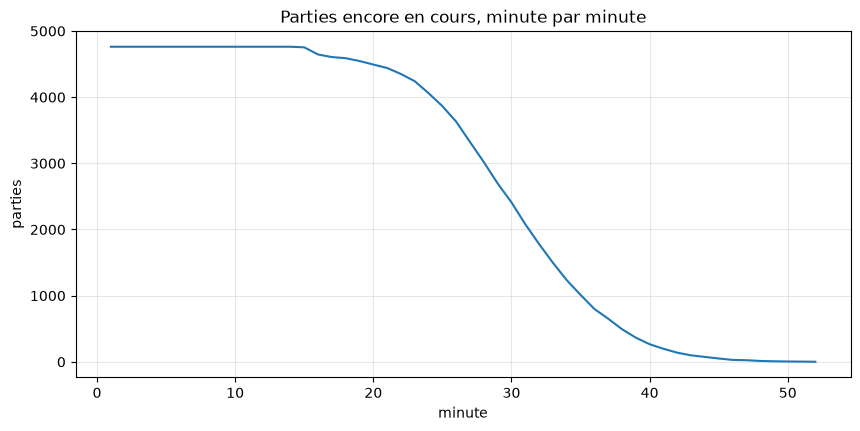

In [2]:
gap = check_against_15(long, games)
print("1. plus grand écart à la minute 15 avec build_features() :", gap.max())

last_kept = long.groupby("match_id")[TIME].max()
duration = games.set_index("match_id").loc[last_kept.index, "duration_min"]
print("2. parties dont la dernière minute gardée n'est pas avant la fin :",
      int((last_kept >= duration).sum()))

overlap = set(train["match_id"]) & set(test["match_id"])
print("3. parties à la fois dans l'entraînement et le test :", len(overlap))

alive = long.groupby(TIME)["match_id"].nunique()
print("4. parties encore en cours aux minutes 10 / 20 / 25 / 30 / 35 / 40 :",
      [int(alive.get(m, 0)) for m in (10, 20, 25, 30, 35, 40)])
ax = alive.plot(title="Parties encore en cours, minute par minute")
ax.set(xlabel="minute", ylabel="parties")
plt.show()

## 2. Des données en 3 dimensions pour le GRU

La logistique et LightGBM lisent le tableau long tel quel (une ligne = une partie à une minute).
Le GRU, lui, lit **une partie entière** à la fois : `to_padded()` range le tableau en 3
dimensions `(parties, minutes, variables)`, comme dans l'aperçu de l'étape 16.

Problème : les parties n'ont pas la même durée. Solution classique, le **padding** : toutes les
parties reçoivent 60 cases de minutes ; après la fin d'une partie, les cases sont remplies de 0
(`X`) et de `NaN` (`y`, « pas de résultat à prédire ici »). Deux garanties :
- le GRU lit les minutes **dans l'ordre**, donc les cases vides **après** la fin ne peuvent pas
  changer ce qu'il dit **avant** ;
- la fonction de perte `masked_bce()` ignore les cases `NaN` : seules les minutes jouées comptent.

In [3]:
X, y, (g, m) = to_padded(train, SEQ_FEATURES + [TIME])
print("X :", X.shape, " (parties, minutes, variables)")
print("y :", y.shape, "    (parties, minutes) : le résultat répété à chaque minute jouée, NaN après")
print(f"cases réellement jouées : {np.mean(~np.isnan(y)):.0%} (le reste, c'est du padding)")
first = 0
print("partie 1, minutes 1 à 3, 3 premières variables :\n", X[first, :3, :3])
print("partie 1, y aux minutes 1, 2, 3 et à la minute 60 :", y[first, [0, 1, 2, 59]])

X : (3809, 60, 17)  (parties, minutes, variables)
y : (3809, 60)     (parties, minutes) : le résultat répété à chaque minute jouée, NaN après
cases réellement jouées : 49% (le reste, c'est du padding)
partie 1, minutes 1 à 3, 3 premières variables :
 [[ -0.011  -0.062  -1.   ]
 [ -0.096  -0.241 -11.   ]
 [ -0.03    0.03   -3.   ]]
partie 1, y aux minutes 1, 2, 3 et à la minute 60 : [ 0.  0.  0. nan]


## 3. Les trois modèles

Les trois ont la même interface (`fit(tableau)` puis `predict(tableau)` → une probabilité par
ligne), ce qui permet de les évaluer avec **exactement** le même code.

- **`PerMinuteLogit`** : une régression logistique (celle de l'étape 13) **par minute**. Chaque
  modèle apprend le poids de l'or *à sa minute* : 1 000 d'or d'avance ne valent pas la même chose
  à 10 et à 35 minutes. Au-delà de 40 minutes, un seul modèle (trop peu de parties).
- **`StackedLGBM`** : **un seul** LightGBM sur toutes les lignes, la minute étant une variable :
  les arbres apprennent seuls que l'effet de l'or dépend du temps.
- **`SequenceGRU`** : le GRU (`WinGRU` dans `src/deep.py`) avec 32 nombres d'état caché. Il voit
  les minutes 1 à t, donc **l'historique** : l'or a-t-il monté ou baissé ces dernières minutes ?

Avant tout, on vérifie la **règle 1** directement sur le GRU : si on modifie les minutes 21 à 60
d'une partie, ses prédictions des minutes 1 à 20 ne doivent **pas bouger d'un iota**. Un GRU
*bidirectionnel* (qui lit aussi la partie à l'envers) échouerait à ce test : il tricherait.

Puis un premier entraînement du GRU, pour voir ses courbes de perte (compter 1 à 3 minutes).

époque  10  train 0.5337  valid 0.5539
époque  20  train 0.5241  valid 0.5502
entraîné en 39 s, meilleure époque 16 sur 26
poids du GRU : 4929


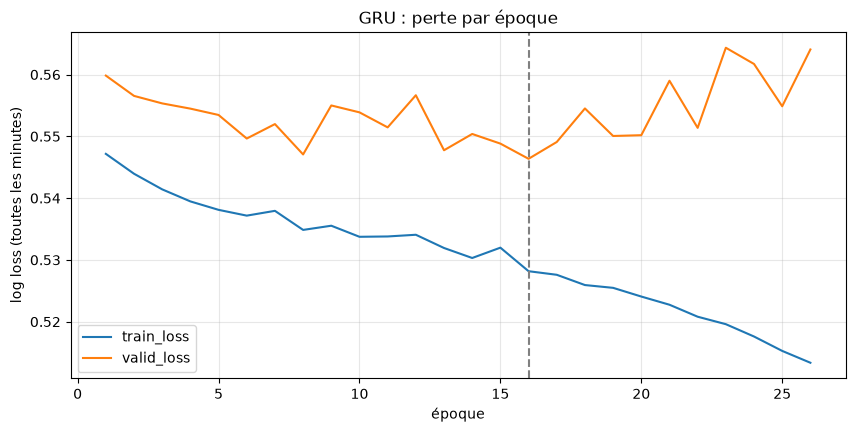

écart max des prédictions minutes 1-20 : 0.0
écart max des prédictions après 20 min : 0.482


In [4]:
t0 = time.time()
gru = SequenceGRU().fit(train, verbose=True)
best = gru.history_.attrs["best_epoch"]
print(f"entraîné en {time.time() - t0:.0f} s, meilleure époque {best} sur {len(gru.history_)}")
print("poids du GRU :", sum(p.numel() for p in gru.net_.parameters()))

ax = gru.history_.plot(x="epoch", y=["train_loss", "valid_loss"])
ax.axvline(best, color="grey", ls="--")
ax.set(xlabel="époque", ylabel="log loss (toutes les minutes)", title="GRU : perte par époque")
plt.show()

# Contrôle de causalité : on change l'avenir d'une partie, le passé ne doit pas bouger.
one = train[train["match_id"] == train["match_id"].iloc[-1]].copy()
p_before = gru.predict(one)
future = one[TIME] > 20
one.loc[future, "gold_k"] += 50          # +50 000 d'or après la minute 20 : absurde, exprès
p_after = gru.predict(one)
print("écart max des prédictions minutes 1-20 :", np.abs(p_after - p_before)[~future.to_numpy()].max())
print("écart max des prédictions après 20 min :", round(float(np.abs(p_after - p_before)[future.to_numpy()].max()), 3))

Lecture attendue : un écart de **0** avant la minute 20 (le GRU ne voit pas l'avenir) et un
grand écart après (il réagit bien à l'or ajouté). Sur la courbe de perte, la validation (les
parties d'entraînement les plus récentes) remonte quand le réseau commence à apprendre le bruit :
l'arrêt précoce garde la meilleure époque.

## 4. Validation croisée chronologique (par partie)

Comme aux étapes 13 et 16 : 5 plis chronologiques sur l'entraînement seulement, chaque pli
valide sur des parties **plus récentes** que toutes celles de son entraînement. La différence :
on découpe la liste des **parties** (`game_folds()`), puis chaque partie emmène toutes ses
minutes. La log loss est calculée sur toutes les (partie, minute) de la validation.

Compter 5 à 15 minutes (le GRU est entraîné 5 fois).

In [5]:
candidates = {
    "Logit par minute": PerMinuteLogit,
    "LightGBM": StackedLGBM,
    "GRU": SequenceGRU,
}
cv = {}
for name, make_model in candidates.items():
    t0 = time.time()
    print(name)
    cv[name] = cross_validate_minutes(make_model, train)
    print(f"  -> moyenne {cv[name]['log_loss'].mean():.4f} ({time.time() - t0:.0f} s)")

summary = pd.DataFrame({name: s[["log_loss", "brier", "auc", "accuracy"]].mean()
                        for name, s in cv.items()}).T.sort_values("log_loss")
display(summary.round(4))
per_fold = pd.DataFrame({name: s["log_loss"].to_numpy() for name, s in cv.items()},
                        index=[f"pli {i}" for i in range(1, 6)])
display(per_fold.round(4))

Logit par minute
  pli 1 : log loss 0.5615
  pli 2 : log loss 0.5087
  pli 3 : log loss 0.5647
  pli 4 : log loss 0.5434
  pli 5 : log loss 0.5520
  -> moyenne 0.5461 (2 s)
LightGBM
  pli 1 : log loss 0.5784
  pli 2 : log loss 0.5211
  pli 3 : log loss 0.5679
  pli 4 : log loss 0.5442
  pli 5 : log loss 0.5591
  -> moyenne 0.5541 (5 s)
GRU
  pli 1 : log loss 0.5616
  pli 2 : log loss 0.5117
  pli 3 : log loss 0.5680
  pli 4 : log loss 0.5466
  pli 5 : log loss 0.5534
  -> moyenne 0.5483 (82 s)


,log_loss,brier,auc,accuracy
Logit par minute,0.5461,0.1862,0.7892,0.7039
GRU,0.5483,0.1870,0.7877,0.7026
LightGBM,0.5541,0.1888,0.7838,0.7006


,Logit par minute,LightGBM,GRU
pli 1,0.5615,0.5784,0.5616
pli 2,0.5087,0.5211,0.5117
pli 3,0.5647,0.5679,0.5680
pli 4,0.5434,0.5442,0.5466
pli 5,0.5520,0.5591,0.5534


## 5. Le test, une seule fois

Chaque modèle est réentraîné sur **tout** l'entraînement, puis prédit les parties du test. On
regarde :
1. la log loss sur **toutes** les (partie, minute) du test ;
2. la log loss **minute par minute** : où chaque modèle gagne-t-il ? (attention : plus la minute
   est grande, moins il reste de parties, et ce sont les plus longues) ;
3. la minute 15, à comparer avec le **0,5242** de l'étape 13 ;
4. le **bootstrap par partie** : l'intervalle de confiance de l'écart GRU − LightGBM et
   GRU − Logit, en tirant des **parties entières** avec remise.

entraînés et évalués en 41 s


,log_loss,brier,auc,accuracy
Logit par minute,0.5327,0.1802,0.8022,0.7202
LightGBM,0.5345,0.1809,0.8010,0.7199
GRU,0.5359,0.1818,0.7984,0.7167


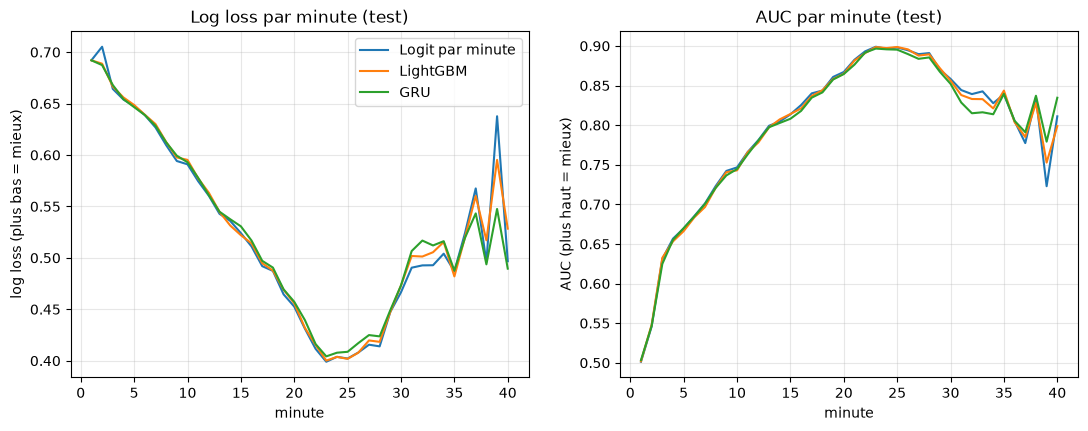

,n_games,Logit par minute log loss,LightGBM log loss,GRU log loss
minute,,,,
5,953,0.6477,0.6486,0.6465
10,953,0.5909,0.5953,0.5929
15,952,0.5241,0.5220,0.5306
20,902,0.4526,0.4558,0.4573
25,784,0.4021,0.4018,0.4087
30,480,0.4666,0.4732,0.4732
35,205,0.4869,0.4820,0.4876


In [6]:
t0 = time.time()
fitted = {name: make_model().fit(train) for name, make_model in candidates.items()}
preds = {name: model.predict(test) for name, model in fitted.items()}
print(f"entraînés et évalués en {time.time() - t0:.0f} s")

final = pd.DataFrame({name: evaluate(test[TARGET], p) for name, p in preds.items()}).T
display(final.sort_values("log_loss").round(4))

by_minute = scores_by_minute(test, preds, minutes=range(1, 41))
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for name in preds:
    by_minute[f"{name} log loss"].plot(ax=axes[0], label=name, color=COLORS[name])
    by_minute[f"{name} AUC"].plot(ax=axes[1], label=name, color=COLORS[name])
axes[0].set(xlabel="minute", ylabel="log loss (plus bas = mieux)", title="Log loss par minute (test)")
axes[1].set(xlabel="minute", ylabel="AUC (plus haut = mieux)", title="AUC par minute (test)")
axes[0].legend()
plt.show()
cols = [c for c in by_minute.columns if "log loss" in c]
display(by_minute.loc[[5, 10, 15, 20, 25, 30, 35], ["n_games"] + cols].round(4))

**Les intervalles de confiance.** Les ~30 lignes d'une partie ne sont **pas** indépendantes :
même résultat, états presque identiques d'une minute à l'autre. Un bootstrap qui tire des
**lignes** (celui de l'étape 13, `paired_bootstrap`) ferait comme si on avait ~30 fois plus de
parties, et donnerait un intervalle beaucoup trop étroit. On le montre pour comparer, puis on
utilise le bon : `bootstrap_games` tire des **parties** (bootstrap « par grappes »).

In [7]:
y_test = test[TARGET].to_numpy()
rows = []
for a, b in [("LightGBM", "GRU"), ("Logit par minute", "GRU"), ("Logit par minute", "LightGBM")]:
    d, lo, hi = bootstrap_games(test, preds[a], preds[b])
    rows.append({"comparaison": f"{b} − {a}", "écart": d, "IC bas (parties)": lo,
                 "IC haut (parties)": hi})
    for lab, minutes in [("1-10", range(1, 11)), ("11-20", range(11, 21)),
                         ("21-30", range(21, 31)), ("31+", range(31, 61))]:
        keep = test[TIME].isin(minutes).to_numpy()
        d, lo, hi = bootstrap_games(test[keep], preds[a][keep], preds[b][keep])
        rows[-1][f"min {lab}"] = f"{d:+.4f} [{lo:+.4f} ; {hi:+.4f}]"
display(pd.DataFrame(rows).set_index("comparaison").round(4))

d, lo, hi = paired_bootstrap(y_test, preds["LightGBM"], preds["GRU"], n_boot=300)
print(f"pour comparer, bootstrap par LIGNES (faux ici) GRU − LightGBM : {d:+.4f} "
      f"[{lo:+.4f} ; {hi:+.4f}], intervalle trop étroit")

at15 = (test[TIME] == 15).to_numpy()
print("\nminute 15 (étape 13 : logistique 0,5242) :",
      {name: round(evaluate(y_test[at15], p[at15])["log_loss"], 4) for name, p in preds.items()})

,écart,IC bas (parties),IC haut (parties),min 1-10,min 11-20,min 21-30,min 31+
comparaison,,,,,,,
GRU − LightGBM,0.0015,-0.0036,0.0064,-0.0007 [-0.0024 ; +0.0011],+0.0023 [-0.0029 ; +0.0076],+0.0047 [-0.0051 ; +0.0144],-0.0036 [-0.0314 ; +0.0246]
GRU − Logit par minute,0.0033,-0.0014,0.0080,-0.0003 [-0.0041 ; +0.0030],+0.0038 [-0.0012 ; +0.0089],+0.0065 [-0.0017 ; +0.0148],+0.0060 [-0.0182 ; +0.0303]
LightGBM − Logit par minute,0.0018,-0.0021,0.0057,+0.0003 [-0.0033 ; +0.0038],+0.0015 [-0.0024 ; +0.0053],+0.0018 [-0.0063 ; +0.0099],+0.0096 [-0.0131 ; +0.0341]


pour comparer, bootstrap par LIGNES (faux ici) GRU − LightGBM : +0.0015 [-0.0001 ; +0.0030], intervalle trop étroit

minute 15 (étape 13 : logistique 0,5242) : {'Logit par minute': 0.5241, 'LightGBM': 0.522, 'GRU': 0.5306}


Comment lire le tableau : un écart **négatif** veut dire que le premier modèle nommé (avant le
« − ») fait **mieux**. Si l'intervalle contient 0, on ne peut pas dire que l'un des deux est
meilleur. Les colonnes « min 1-10 » … « min 31+ » font la même comparaison par tranche de minutes.

## 6. Une partie racontée par les trois modèles

La courbe que montrera l'appli. On prend la partie du test avec le plus beau **retournement** :
le futur vainqueur a eu la plus faible probabilité de gagner selon le GRU à un moment de la
partie. L'écart d'or (en gris, axe de droite) aide à lire la courbe.

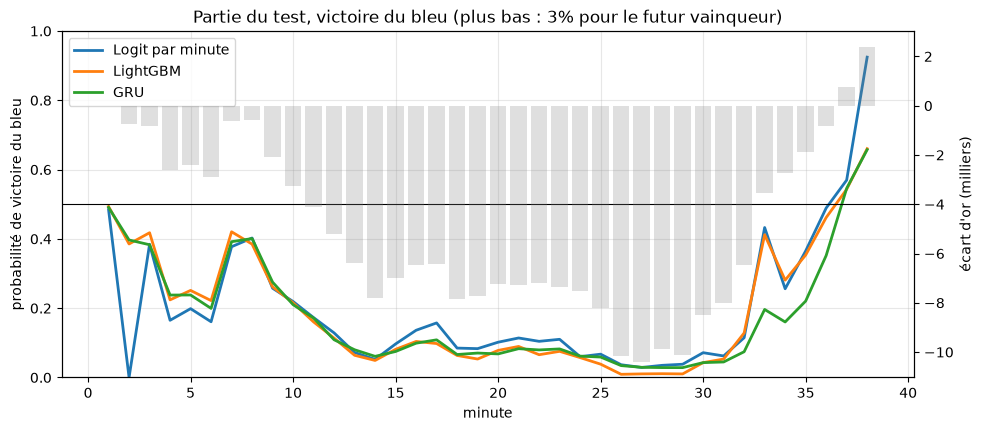

partie : EUW1_8024975419


,gold_k,dragons_diff,barons_diff,Logit par minute,LightGBM,GRU
minute,,,,,,
1,-0.00,0,0,0.48,0.49,0.49
4,-2.61,0,0,0.17,0.22,0.24
7,-0.61,1,0,0.38,0.42,0.39
10,-3.27,1,0,0.22,0.22,0.21
13,-6.37,0,0,0.07,0.06,0.08
16,-6.48,0,0,0.14,0.10,0.10
19,-7.72,-1,0,0.08,0.05,0.07
22,-7.18,-1,0,0.10,0.07,0.08
25,-8.20,-2,0,0.07,0.04,0.06


In [8]:
view = test[["match_id", TIME, "gold_k", "barons_diff", "dragons_diff", TARGET]].copy()
for name, p in preds.items():
    view[name] = p
# probabilité donnée au FUTUR vainqueur, minute par minute
view["p_winner"] = np.where(view[TARGET] == 1, view["GRU"], 1 - view["GRU"])
lowest = view.groupby("match_id")["p_winner"].min()
game_id = lowest.idxmin()
one = view[view["match_id"] == game_id]

fig, ax = plt.subplots(figsize=(11, 4.5))
for name in preds:
    ax.plot(one[TIME], one[name], label=name, color=COLORS[name], lw=2)
ax.axhline(0.5, color="black", lw=0.8)
ax.set(ylim=(0, 1), xlabel="minute", ylabel="probabilité de victoire du bleu",
       title=f"Partie du test, {'victoire' if one[TARGET].iloc[0] else 'défaite'} du bleu "
             f"(plus bas : {lowest.min():.0%} pour le futur vainqueur)")
ax2 = ax.twinx()
ax2.bar(one[TIME], one["gold_k"], color="grey", alpha=0.25)
ax2.set_ylabel("écart d'or (milliers)")
ax2.grid(False)
ax.legend(loc="upper left")
plt.show()
print("partie :", game_id)
display(one.set_index(TIME)[["gold_k", "dragons_diff", "barons_diff"] + list(preds)].iloc[::3].round(2))

## 7. Conclusions

*(Exécuté le 3 nov. 2026 sur la vraie base : 4 762 parties, 141 149 lignes (partie, minute) ; entraînement 3 809 parties, test 953.)*

**1. Les contrôles : deux écarts, tous les deux bénins (vérifiés dans les fichiers bruts de data/raw).**
- Écart de **2,0** à la minute 15 avec `build_features()` : il vient de `first_blood` (et une fois de `first_tower`) dans **8 parties sur 5 000** où les deux équipes font leur premier kill à la **même milliseconde** (un échange). Les deux codes départagent l'égalité au hasard, l'un dit +1, l'autre −1 : ni l'un ni l'autre n'est faux. Toutes les autres variables sont identiques.
- **17 parties** dont la dernière minute gardée n'est « pas avant la fin » : leur durée tombe pile sur une minute (ex. 1 680 s = 28:00) et la frame de la minute 28 est enregistrée à 28:00,5, une demi-seconde avant la fin. C'est un artefact d'arrondi de `gameDuration`, pas une fuite : la frame de fin elle-même est bien retirée.
- Pas de partie coupée entre entraînement et test (0), et le GRU ne voit pas l'avenir (écart 0,0 sur les minutes 1 à 20 quand on modifie la suite).

**2. Les trois modèles se valent : le GRU n'apporte rien.** Log loss sur toutes les (partie, minute) :

| | Validation croisée (5 plis) | Test |
|---|---|---|
| Logistique par minute | **0,5461** | **0,5327** (AUC 0,802, 72,0 %) |
| GRU | 0,5483 | 0,5359 (AUC 0,798) |
| LightGBM empilé | 0,5541 | 0,5345 (AUC 0,801) |

Bootstrap par partie sur le test : GRU − LightGBM **+0,0015** (IC 95 % −0,0036 à +0,0064), GRU − Logit **+0,0033** (−0,0014 à +0,0080), LightGBM − Logit +0,0018 (−0,0021 à +0,0057). Les trois intervalles contiennent 0 : **aucune différence démontrable**, et la logistique par minute est même légèrement devant, en validation croisée comme au test. Par tranche de minutes non plus, aucun écart net.

**3. Pourquoi l'historique n'aide pas.** Les variables sont déjà **cumulées** depuis le début (or total, tours, dragons, barons) : la photo de la minute t contient déjà presque toute l'histoire utile. La seule chose que le GRU voit en plus, la dynamique des dernières minutes, n'ajoute rien de mesurable avec ~3 800 parties d'entraînement. C'est la même leçon qu'aux étapes 13 et 16 : un modèle plus souple ne bat pas une logistique quand le signal est presque linéaire et les données peu nombreuses.

**4. Contrôle de cohérence avec l'étape 13.** À la minute 15, la logistique par minute fait **0,5241**, le même score que le modèle de l'étape 13 (0,5242) : deux chemins différents, le même résultat.

**5. La difficulté dépend de la minute.** Log loss de la logistique : 0,648 à 5 min (presque une pièce de monnaie, 0,693), 0,591 à 10 min, 0,524 à 15 min, 0,453 à 20 min, **0,402 à 25 min**, puis elle **remonte** : 0,467 à 30 min, 0,487 à 35 min. Ce n'est pas le modèle qui se dégrade : à 35 min il ne reste que 205 parties sur 953, celles qu'aucune équipe n'a su finir, souvent serrées et décidées par un seul combat (biais de sélection).

**6. Une partie racontée.** Dans la partie du test choisie à la partie 6, le bleu a 10 000 d'or de retard, 2 dragons et 1 baron de moins à 28 minutes : les trois modèles lui donnent 1 à 4 % de chances. Il repasse devant (750 d'or d'avance à 37 min) et gagne. Les trois courbes se suivent de près : elles réagissent aux mêmes informations.

**7. Décision.** Pour la courbe minute par minute de l'appli Streamlit, on garde le modèle le plus simple : la **logistique par minute** (`PerMinuteLogit`). Elle est la meilleure en validation croisée, aussi bonne que les autres au test, rapide à entraîner (2 s contre ~80 s pour le GRU en validation croisée) et explicable avec les contributions de l'étape 14, minute par minute. Le GRU reste dans le dépôt comme expérience documentée.

**Limites.** Une seule taille de GRU testée (32), réglages choisis à l'avance ; ~3 800 parties d'entraînement, peu pour un réseau récurrent ; pas de variables de position ni de vision, qui sont justement ce qu'un modèle séquentiel pourrait exploiter.